In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from data import sample_eight_gaussians
from models import EnergyModelToy, EnergyModelToy1

data = sample_eight_gaussians(
    n_samples=1000,
    seed=42,
)

model = EnergyModelToy()

energy = model(data)

print(data.shape)
print(energy.shape)

print(data[:5])
print(energy[:5])

torch.Size([1000, 2])
torch.Size([1000])
tensor([[-0.0621, -2.0793],
        [-1.4904,  1.5864],
        [-1.9640, -0.1186],
        [-0.1220, -1.9788],
        [ 0.2345,  2.0897]])
tensor([ 0.0380, -0.1483, -0.1219,  0.0318, -0.0671], grad_fn=<SliceBackward0>)


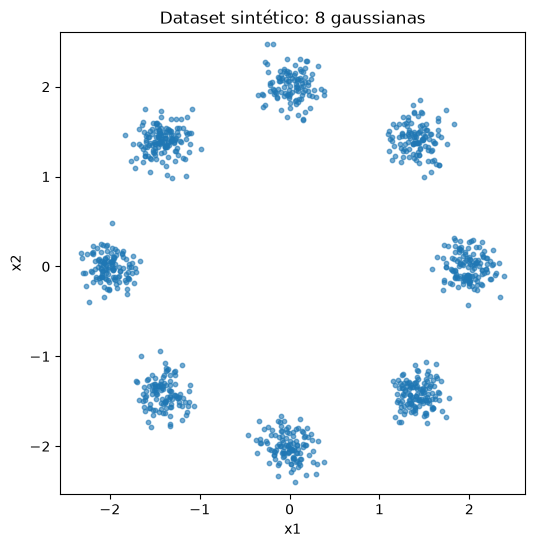

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(
    data[:, 0],
    data[:, 1],
    s=10,
    alpha=0.6,
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dataset sintético: 8 gaussianas")
plt.axis("equal")
plt.show()

In [3]:
from data import (
    sample_eight_gaussians,
    make_grid,
)

grid, xx, yy = make_grid(
    x_min=-4,
    x_max=4,
    y_min=-4,
    y_max=4,
    resolution=200,
)

print(grid.shape)
print(xx.shape)
print(yy.shape)

torch.Size([40000, 2])
torch.Size([200, 200])
torch.Size([200, 200])


In [4]:
import torch

In [5]:
with torch.no_grad():
    grid_energies = model(grid)

energy_map = grid_energies.reshape(xx.shape)

print(grid_energies.shape)
print(energy_map.shape)

torch.Size([40000])
torch.Size([200, 200])


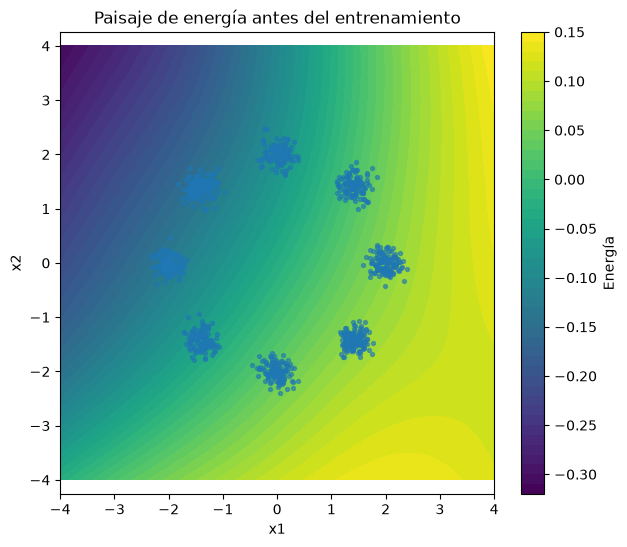

In [6]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía antes del entrenamiento")
plt.axis("equal")

plt.show()

In [7]:
from sampling import langevin_sampling

x_init = 8 * torch.rand(200, 2) - 4

trajectory = langevin_sampling(
    model=model,
    x_init=x_init,
    n_steps=1000,
    step_size=0.05,
    noise_scale=0.01,
    require_trajectory=True,
)
import ipywidgets as widgets
from IPython.display import display


def plot_langevin_step(step):

    points = trajectory[step]

    plt.figure(figsize=(7, 6))

    contour = plt.contourf(
        xx.numpy(),
        yy.numpy(),
        energy_map.numpy(),
        levels=50,
    )

    plt.scatter(
        points[:, 0].numpy(),
        points[:, 1].numpy(),
        s=15,
    )

    plt.colorbar(contour, label="Energía")

    plt.xlabel("x1")
    plt.ylabel("x2")

    plt.title(
        f"Langevin - paso {step}"
    )

    plt.xlim(-4, 4)
    plt.ylim(-4, 4)

    plt.show()

widgets.interact(
    plot_langevin_step,
    step=widgets.IntSlider(
        min=0,
        max=1000,
        step=1,
        value=0,
        description="Paso:",
    ),
)

interactive(children=(IntSlider(value=0, description='Paso:', max=1000), Output()), _dom_classes=('widget-inte…

<function __main__.plot_langevin_step(step)>

In [8]:
from training import train_toy_langevin, train_toy_dsm, train_toy_pcd

Epoch 0 | Loss: 0.0125 | E_real: 0.0472 | E_model: 0.0348


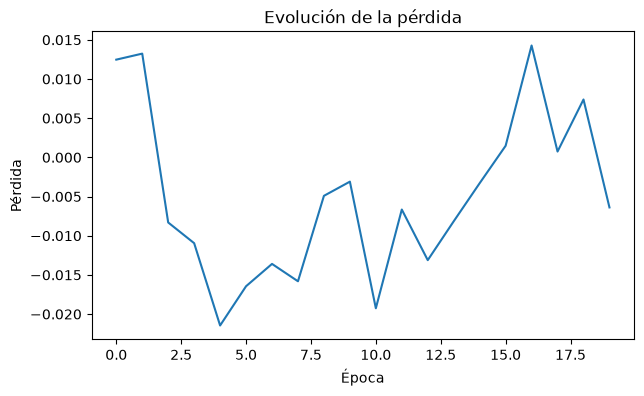

In [9]:

model = EnergyModelToy1()
losses = train_toy_langevin(
    model=model,
    data=data,
    n_epochs=20,
    batch_size=128,
    learning_rate=1e-3,
    langevin_steps=1000,
    step_size=0.1,
    noise_scale=0.1,
)

plt.figure(figsize=(7, 4))

plt.plot(losses)

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Evolución de la pérdida")

plt.show()

In [10]:
with torch.no_grad():
    grid_energies = model(grid)

energy_map = grid_energies.reshape(xx.shape)

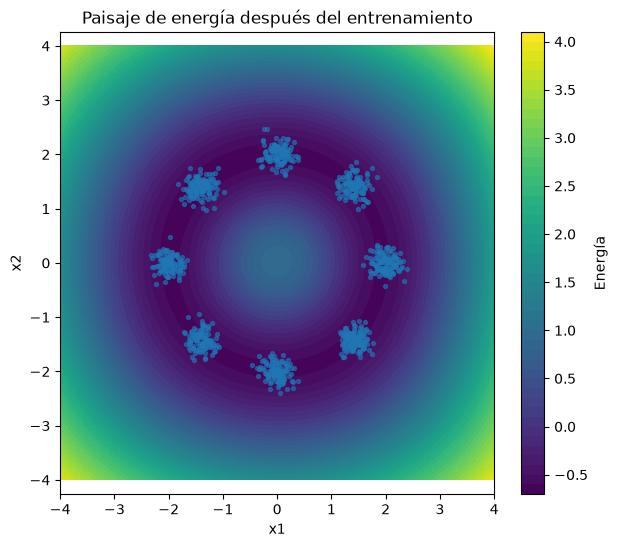

In [11]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(contour, label="Energía")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía después del entrenamiento")

plt.axis("equal")
plt.show()

In [12]:
x_init = 8 * torch.rand(
    200,
    2,
) - 4

trajectory_langevin = langevin_sampling(
    model=model,
    x_init=x_init,
    n_steps=1000,
    step_size=0.05,
    noise_scale=0.01,
    require_trajectory=True,
)

In [13]:
import matplotlib.pyplot as plt
import ipywidgets as widgets


def plot_langevin_step_dsm(step):

    points = trajectory_langevin[step].detach().cpu()

    plt.figure(figsize=(7, 6))

    plt.scatter(
        data[:, 0].cpu(),
        data[:, 1].cpu(),
        s=10,
        alpha=0.3,
        label="Real data",
    )

    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=15,
        label="Langevin samples",
    )

    plt.xlabel("x1")
    plt.ylabel("x2")

    plt.title(
        f"DSM EBM - Langevin step {step}"
    )

    plt.xlim(-4, 4)
    plt.ylim(-4, 4)

    plt.legend()
    plt.show()


widgets.interact(
    plot_langevin_step_dsm,
    step=widgets.IntSlider(
        min=0,
        max=trajectory_langevin.shape[0] - 1,
        step=1,
        value=0,
        description="Paso:",
    ),
)

interactive(children=(IntSlider(value=0, description='Paso:', max=1000), Output()), _dom_classes=('widget-inte…

<function __main__.plot_langevin_step_dsm(step)>

In [11]:
model_dsm = EnergyModelToy()

In [12]:
losses_dsm = train_toy_dsm(
    model=model_dsm,
    data=data,
    n_epochs=100,
    batch_size=128,
    learning_rate=1e-2,
    sigma=0.3,
)

Epoch 0 | Loss DSM: 21.7458
Epoch 10 | Loss DSM: 13.4935
Epoch 20 | Loss DSM: 13.2365
Epoch 30 | Loss DSM: 11.1342
Epoch 40 | Loss DSM: 9.5293
Epoch 50 | Loss DSM: 9.4224
Epoch 60 | Loss DSM: 9.7306
Epoch 70 | Loss DSM: 7.9590
Epoch 80 | Loss DSM: 8.6415
Epoch 90 | Loss DSM: 8.6464


In [13]:
with torch.no_grad():
    grid_energies_dsm = model_dsm(grid)

energy_map_dsm = grid_energies_dsm.reshape(xx.shape)

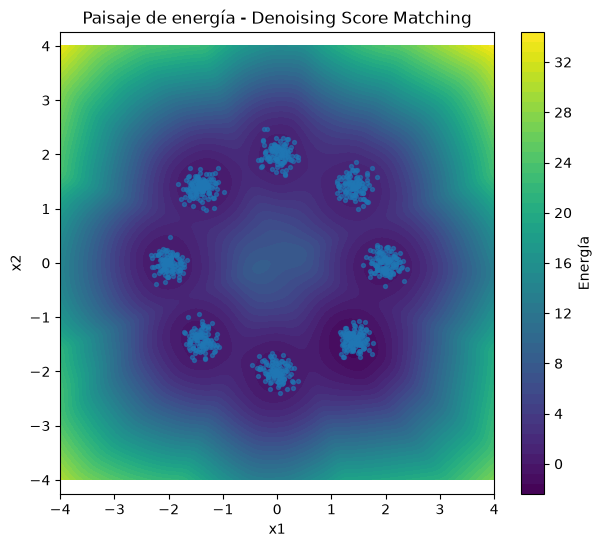

In [14]:
plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map_dsm.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía - Denoising Score Matching")

plt.axis("equal")
plt.show()

In [ ]:
x_init = 8 * torch.rand(
    200,
    2,
) - 4

trajectory_dsm = langevin_sampling(
    model=model_dsm,
    x_init=x_init,
    n_steps=1000,
    step_size=0.05,
    noise_scale=0.01,
    require_trajectory=True,
)

import matplotlib.pyplot as plt
import ipywidgets as widgets


def plot_langevin_step_dsm(step):

    points = trajectory_dsm[step].detach().cpu()

    plt.figure(figsize=(7, 6))

    plt.scatter(
        data[:, 0].cpu(),
        data[:, 1].cpu(),
        s=10,
        alpha=0.3,
        label="Real data",
    )

    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=15,
        label="Langevin samples",
    )

    plt.xlabel("x1")
    plt.ylabel("x2")

    plt.title(
        f"DSM EBM - Langevin step {step}"
    )

    plt.xlim(-4, 4)
    plt.ylim(-4, 4)

    plt.legend()
    plt.show()


widgets.interact(
    plot_langevin_step_dsm,
    step=widgets.IntSlider(
        min=0,
        max=trajectory_dsm.shape[0] - 1,
        step=1,
        value=0,
        description="Paso:",
    ),
)

interactive(children=(IntSlider(value=0, description='Paso:', max=1000), Output()), _dom_classes=('widget-inte…

<function __main__.plot_langevin_step_dsm(step)>

Epoch 0 | Loss PCD: 0.0629 | E_real: 0.0294 | E_model: 0.0160
Epoch 10 | Loss PCD: 0.2706 | E_real: -0.0676 | E_model: -0.3364


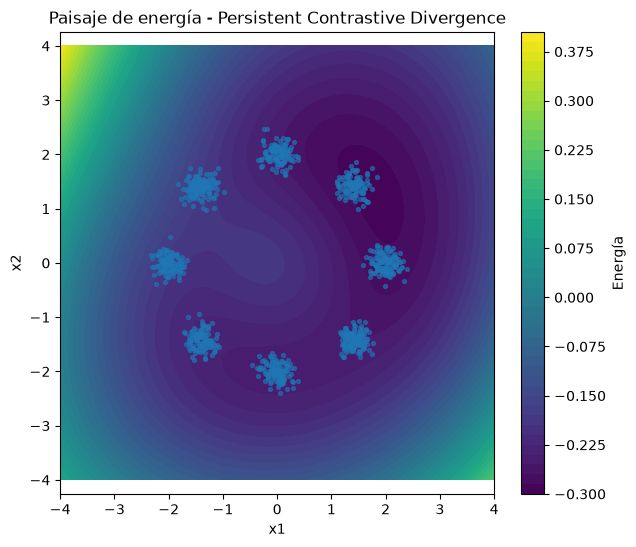

In [7]:
model_pcd = EnergyModelToy1()


losses_pcd, persistent_samples = train_toy_pcd(
    model=model_pcd,
    data=data,
    n_epochs=20,
    batch_size=128,
    learning_rate=1e-3,
    langevin_steps=100,
    step_size=0.1,
    noise_scale=0.01,
)

with torch.no_grad():
    grid_energies_pcd = model_pcd(grid)

energy_map_pcd = grid_energies_pcd.reshape(xx.shape)


plt.figure(figsize=(7, 6))

contour = plt.contourf(
    xx.numpy(),
    yy.numpy(),
    energy_map_pcd.numpy(),
    levels=50,
)

plt.scatter(
    data[:, 0].numpy(),
    data[:, 1].numpy(),
    s=8,
    alpha=0.6,
)

plt.colorbar(
    contour,
    label="Energía",
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Paisaje de energía - Persistent Contrastive Divergence")

plt.axis("equal")
plt.show()